Q1.

Using device: cuda


100.0%


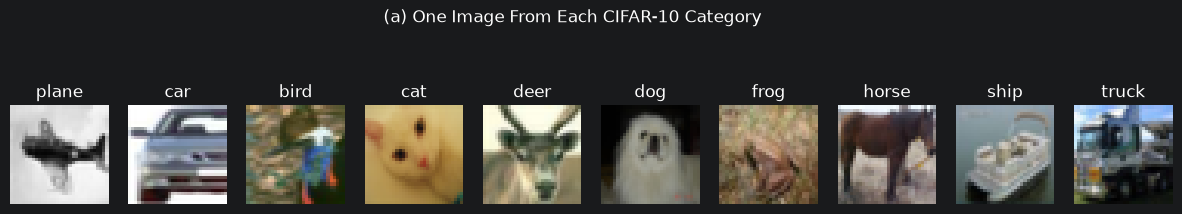


--- Starting Grid Search ---
Testing LR: 0.001, Hidden Size: 256...
-> Validation Accuracy: 0.5031
Testing LR: 0.001, Hidden Size: 512...
-> Validation Accuracy: 0.5011
Testing LR: 0.005, Hidden Size: 256...
-> Validation Accuracy: 0.4422
Testing LR: 0.005, Hidden Size: 512...
-> Validation Accuracy: 0.4339

Best Hyperparameters Found: {'lr': 0.001, 'hidden_size': 256}

--- Training Tuned Network ---


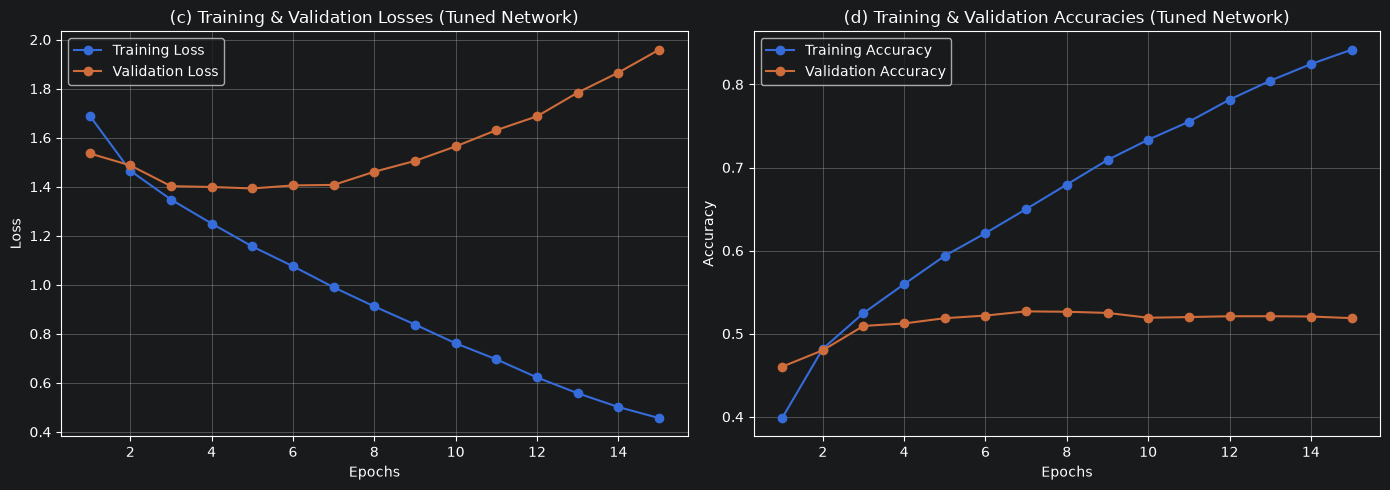

In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

full_train_dataset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                                  download=True, transform=transform)

train_size = int(0.7 * len(full_train_dataset))
val_size = len(full_train_dataset) - train_size
train_dataset, val_dataset = random_split(full_train_dataset, [train_size, val_size],
                                          generator=torch.Generator().manual_seed(42))

train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=128, shuffle=False)

classes = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

def imshow(img, title):
    img = img / 2 + 0.5
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.title(title)
    plt.axis('off')

class_images = {}
for inputs, labels in train_loader:
    for i in range(len(labels)):
        label = labels[i].item()
        if label not in class_images:
            class_images[label] = inputs[i]
        if len(class_images) == 10:
            break
    if len(class_images) == 10:
        break

plt.figure(figsize=(15, 3))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    imshow(class_images[i], classes[i])
plt.suptitle('(a) One Image From Each CIFAR-10 Category')
plt.show()

class FullyConnectedNN(nn.Module):
    def __init__(self, hidden_size=512):
        super(FullyConnectedNN, self).__init__()
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(32 * 32 * 3, hidden_size)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(hidden_size, 256)
        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3(x)
        return x

def train_and_evaluate(model, train_loader, val_loader, lr, epochs=5):
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(model.parameters(), lr=lr)

    history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct_train, total_train = 0.0, 0, 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()

        history['train_loss'].append(running_loss / len(train_loader))
        history['train_acc'].append(correct_train / total_train)

        model.eval()
        val_loss, correct_val, total_val = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        history['val_loss'].append(val_loss / len(val_loader))
        history['val_acc'].append(correct_val / total_val)

    return history

print("\n--- Starting Grid Search ---")
learning_rates = [0.001, 0.005]
hidden_sizes = [256, 512]
best_val_acc = 0
best_params = {}

for lr in learning_rates:
    for hidden_size in hidden_sizes:
        print(f"Testing LR: {lr}, Hidden Size: {hidden_size}...")
        model = FullyConnectedNN(hidden_size=hidden_size).to(device)

        history = train_and_evaluate(model, train_loader, val_loader, lr, epochs=3)
        final_val_acc = history['val_acc'][-1]

        print(f"-> Validation Accuracy: {final_val_acc:.4f}")

        if final_val_acc > best_val_acc:
            best_val_acc = final_val_acc
            best_params = {'lr': lr, 'hidden_size': hidden_size}

print(f"\nBest Hyperparameters Found: {best_params}")

print("\n--- Training Tuned Network ---")
final_model = FullyConnectedNN(hidden_size=best_params['hidden_size']).to(device)

final_history = train_and_evaluate(final_model, train_loader, val_loader,
                                   lr=best_params['lr'], epochs=15)

epochs_range = range(1, 16)
plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)
plt.    plot(epochs_range, final_history['train_loss'], label='Training Loss', marker='o')
plt.plot(epochs_range, final_history['val_loss'], label='Validation Loss', marker='o')
plt.title('(c) Training & Validation Losses (Tuned Network)')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, final_history['train_acc'], label='Training Accuracy', marker='o')
plt.plot(epochs_range, final_history['val_acc'], label='Validation Accuracy', marker='o')
plt.title('(d) Training & Validation Accuracies (Tuned Network)')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

Q2.

Using device: cuda



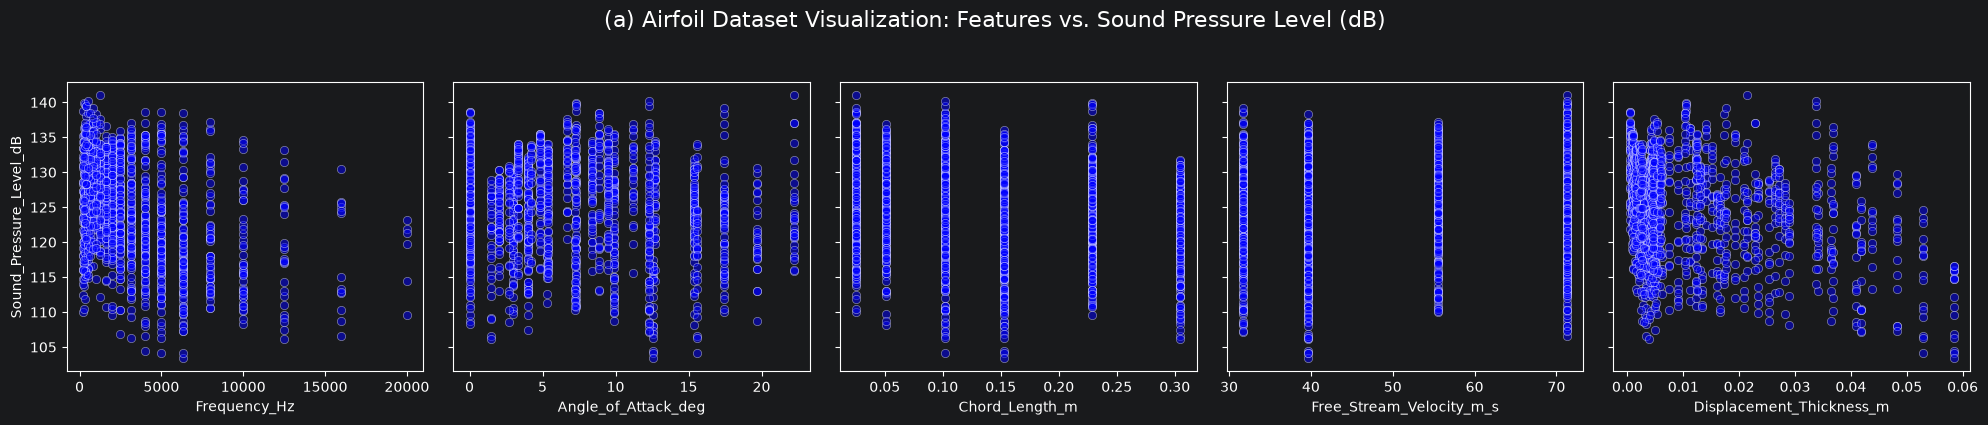


--- Final Results ---
Test Set Mean Squared Error: 3.2155
(c) Coefficient of Determination (R^2): 0.9319


In [22]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score
import torch
import torch.nn as nn
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}\n")

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00291/airfoil_self_noise.dat"
columns = [
    'Frequency_Hz',
    'Angle_of_Attack_deg',
    'Chord_Length_m',
    'Free_Stream_Velocity_m_s',
    'Displacement_Thickness_m',
    'Sound_Pressure_Level_dB'
]

df = pd.read_csv(url, sep='\t', names=columns)

fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)
fig.suptitle('(a) Airfoil Dataset Visualization: Features vs. Sound Pressure Level (dB)', fontsize=16, y=1.05)

features = columns[:-1]
target = columns[-1]

for i, feature in enumerate(features):
    sns.scatterplot(ax=axes[i], x=df[feature], y=df[target], alpha=0.5, color='b')
    axes[i].set_xlabel(feature)
    if i == 0:
        axes[i].set_ylabel(target)
    else:
        axes[i].set_ylabel('')

plt.tight_layout()
plt.show()


X = df[features].values
y = df[target].values.reshape(-1, 1)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32).to(device)
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32).to(device)
y_train_t = torch.tensor(y_train, dtype=torch.float32).to(device)
y_test_t = torch.tensor(y_test, dtype=torch.float32).to(device)

class AirfoilNN(nn.Module):
    def __init__(self, input_dim=5):
        n_dim = 128
        super(AirfoilNN, self).__init__()
        self.fc1 = nn.Linear(input_dim, n_dim)
        self.fc2 = nn.Linear(n_dim, n_dim)
        self.fc3 = nn.Linear(n_dim, n_dim)
        self.fc4 = nn.Linear(n_dim, n_dim)
        self.fc5 = nn.Linear(n_dim, n_dim)
        self.fc6 = nn.Linear(n_dim, 1)
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.fc1(x))
        x = self.relu(self.fc2(x))
        x = self.relu(self.fc3(x))
        x = self.relu(self.fc4(x))
        x = self.relu(self.fc5(x))
        x = self.fc6(x)
        return x

model = AirfoilNN().to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)

epochs = 5000

history_loss = []
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    predictions = model(X_train_t)
    loss = criterion(predictions, y_train_t)

    loss.backward()
    optimizer.step()

    history_loss.append(loss.item())

model.eval()
with torch.no_grad():
    y_pred_t = model(X_test_t)
    test_loss = criterion(y_pred_t, y_test_t)

y_pred_np = y_pred_t.cpu().numpy()
y_test_np = y_test_t.cpu().numpy()

r2 = r2_score(y_test_np, y_pred_np)

print("\n--- Final Results ---")
print(f"Test Set Mean Squared Error: {test_loss.item():.4f}")
print(f"(c) Coefficient of Determination (R^2): {r2:.4f}")